In [1]:
# Interfaz
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path
import numpy as np
import scipy.signal as sig
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF
import Funciones as Funciones
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
%config InlineBackend.figure_format = 'svg'

#========================================================================================================================================
# Variables generales
#========================================================================================================================================
cmap = Funciones.parula_map
color_ACC = 'blue'
color_EGG = 'orange'
color_dEGG = 'g'
color_OVV = 'magenta'
color_speech = 'black'
legend_loc = 'upper right'
color1 = 'red'
color2 = 'blue'
color3 = 'k'
color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'
line_width = 1.5

In [2]:
fc = FileChooser('OVV sintetica')
fc.layout = widgets.Layout(width='1000px')
display(fc)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\OVV sintetica', filename='', title='', show_hidden=F…

In [69]:
archivo = Path(fc.selected)
nombre_archivo = archivo.name
datos = np.loadtxt(archivo, delimiter='\t', skiprows=1)
fs_r = 8000
to = 0
tf = 50
tiempos = np.arange(to, tf, 1000/fs_r)

señal_MBK  = datos[:, 0] - np.mean(datos[:, 0])
señal_MBK  = Funciones.Detrend(tiempos,señal_MBK)
 
flujo_OVV  = datos[:, 3] - np.mean(datos[:, 3])
flujo_OVV  = Funciones.Detrend(tiempos,flujo_OVV)
dflujo_OVV = np.gradient(flujo_OVV) 

flujo_referencia  = datos[:, 2]
flujo_referencia  = Funciones.Detrend(tiempos,flujo_referencia)
dflujo_referencia = np.gradient(flujo_referencia)

In [90]:
resultado_NMF = NMF.NNMF_GIF(señal=señal_MBK,
                                    dEGG = señal_MBK,
                                    tiempos=tiempos,
                                    fs=fs_r,
                                    norma="frobenius",
                                    pre_iteraciones=0,
                                    iteraciones=25000,
                                    p_filtro=12,
                                    alfa=0.96,
                                    beta=0.55,
                                    pre_enfasis=True,
                                    duracion=5.5,
                                    guardar_proceso=True,
                                    ventana = 'Rectangular'
                                    )
resultado_NMF.flujo1 = Funciones.Detrend(resultado_NMF.tiempos_gve,resultado_NMF.flujo1)
resultado_NMF.dflujo1 = np.gradient(resultado_NMF.flujo1)
resultado_NMF.flujo2 = Funciones.Detrend(resultado_NMF.tiempos_gve,resultado_NMF.flujo2)
resultado_NMF.dflujo2 = np.gradient(resultado_NMF.flujo2)

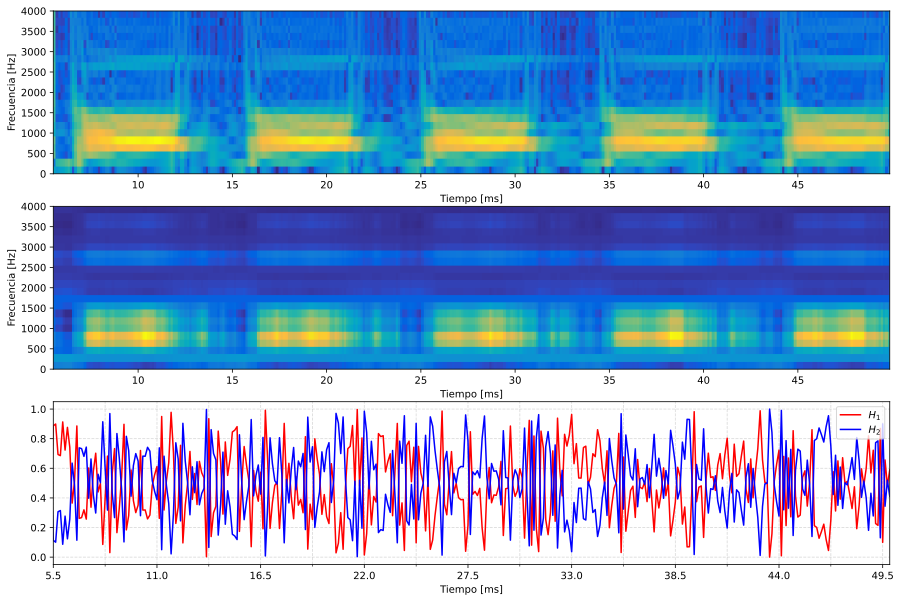

In [91]:
fig,(ax1,ax2,ax3) = plt.subplots(3,1,figsize=(15,10))
ax1.imshow(resultado_NMF.espectrograma,
                cmap=cmap,
                origin='lower',
                aspect='auto',
                extent=[resultado_NMF.to_espectrograma, resultado_NMF.tf_espectrograma,
                        resultado_NMF.fo_espectrograma, resultado_NMF.ff_espectrograma])
ax1.set_ylabel('Frecuencia [Hz]')
ax1.set_xlabel("Tiempo [ms]")

ax2.imshow(resultado_NMF.espectrograma_aprox,
                cmap=cmap,
                origin='lower',
                aspect='auto',
                extent=[resultado_NMF.to_espectrograma, resultado_NMF.tf_espectrograma,
                        resultado_NMF.fo_espectrograma, resultado_NMF.ff_espectrograma])
ax2.set_ylabel('Frecuencia [Hz]')
ax2.set_xlabel("Tiempo [ms]");

ax3.plot(resultado_NMF.tiempos_espectrograma,resultado_NMF.H1,color=color1,label=r'$H_1$')
ax3.plot(resultado_NMF.tiempos_espectrograma,resultado_NMF.H2,color=color2,label=r'$H_2$')
ax3.set_xlim(resultado_NMF.to_espectrograma,resultado_NMF.tf_espectrograma)
ax3.set_xticks(np.arange(resultado_NMF.to_espectrograma,resultado_NMF.tf_espectrograma,resultado_NMF.duracion_ventana))
ax3.set_xticks(np.arange(resultado_NMF.to_espectrograma,resultado_NMF.tf_espectrograma,resultado_NMF.duracion_ventana/2),minor=True)
ax3.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
ax3.legend(loc=legend_loc)
ax3.set_xlabel('Tiempo [ms]');

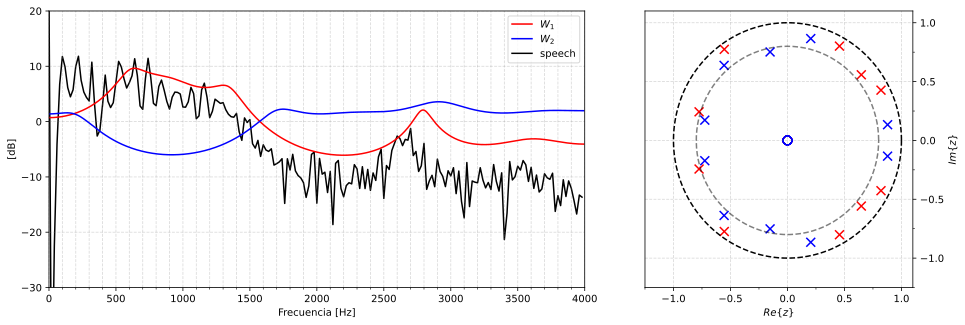

In [92]:
fig = plt.figure(figsize=(12,5))
widths  = [1,0.5]
heights = [1]
gs  = fig.add_gridspec(1, 2,width_ratios=widths,height_ratios=heights,left=0,right=1,wspace=0.15,hspace=0.25)

# Espectrograma
ax1 = fig.add_subplot(gs[0,0])
# Espectrograma aproximado
ax2 = fig.add_subplot(gs[0,1])

# ------------- Respuesta en frecuencia
theta = np.linspace(0, 2*np.pi, 200)
fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
fw1,hw1 = sig.freqz([1],resultado_NMF.a_W1,fs=fs_r)
fw2,hw2 = sig.freqz([1],resultado_NMF.a_W2,fs=fs_r)
ax1.plot(fw1, 10*np.log10(np.abs(hw1)), label=r'$W_1$', color=color1)
ax1.plot(fw2, 10*np.log10(np.abs(hw2)), label=r'$W_2$', color=color2)
ax1.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='speech', color=color3, zorder=-1)
ax1.set_xlim(0,fs_r/2)
ax1.set_xticks(np.arange(0, fs_r/2, 100), minor=True)
ax1.grid(True, linestyle='dashed', color='gray', alpha=0.3, which='both')
ax1.set_xlabel('Frecuencia [Hz]')
ax1.set_ylabel('[dB]')
ax1.set_ylim([-30,20])
ax1.legend(loc='upper right')
# ------------- Polos y ceros   
ax2.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
ax2.plot(0.8*np.cos(theta), 0.8*np.sin(theta), 'k--', alpha=0.5)
ax2.yaxis.tick_right()
ax2.yaxis.set_label_position("right")
ax2.scatter(np.real(resultado_NMF.ceros_W1), np.imag(resultado_NMF.ceros_W1),s=80, facecolors='none', edgecolors=color1, label='Ceros')
ax2.scatter(np.real(resultado_NMF.polos_W1), np.imag(resultado_NMF.polos_W1),s=80, marker='x', color=color1, label='Polos')
ax2.scatter(np.real(resultado_NMF.ceros_W2), np.imag(resultado_NMF.ceros_W2),s=80, facecolors='none', edgecolors=color2, label='Ceros')
ax2.scatter(np.real(resultado_NMF.polos_W2), np.imag(resultado_NMF.polos_W2),s=80, marker='x', color=color2, label='Polos')
ax2.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
ax2.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
ax2.set_ylabel(r"$Im\{z\}$")
ax2.set_xlabel(r"$Re\{z\}$")
ax2.grid(True, linestyle='dashed', color='gray', alpha=0.3)



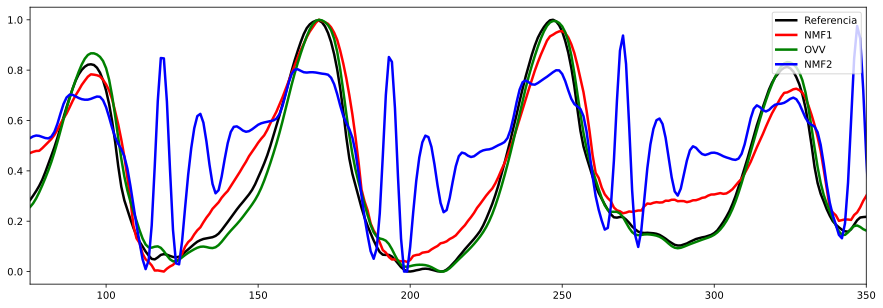

In [93]:
fig,ax1 = plt.subplots(figsize=(15,5))
line_width = 2.5
ax1.plot(flujo_referencia,color='k',label = 'Referencia',linewidth=line_width)
se,sr,t= Funciones.Sincronizar2(resultado_NMF.flujo1,flujo_referencia,tiempos)
ax1.plot(se,color='r',label='NMF1',linewidth=line_width);
se,sr,t= Funciones.Sincronizar2(flujo_OVV,flujo_referencia,tiempos)
ax1.plot(se,color='green',label = 'OVV',linewidth=line_width)
se,sr,t= Funciones.Sincronizar2(resultado_NMF.flujo2,flujo_referencia,tiempos)
ax1.plot(se,color='b',label='NMF2',linewidth=line_width);
ax1.legend(loc='upper right')
ax1.set_xlim([75,350]);

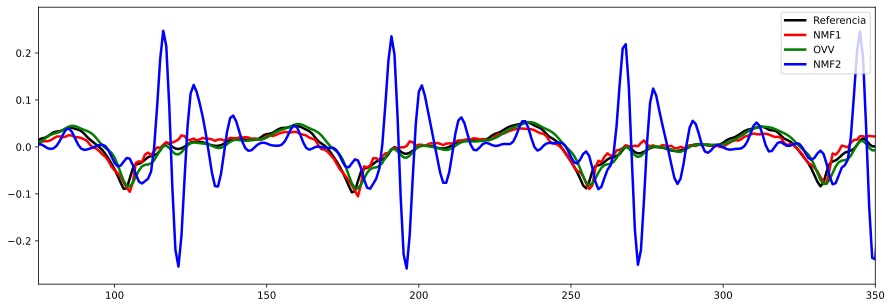

In [94]:
fig,ax1 = plt.subplots(figsize=(15,5))
line_width = 2.5
ax1.plot(dflujo_referencia,color='k',label = 'Referencia',linewidth=line_width)
se,sr,t= Funciones.Sincronizar2(resultado_NMF.dflujo1,dflujo_referencia,tiempos)
ax1.plot(se,color='r',label='NMF1',linewidth=line_width);
se,sr,t= Funciones.Sincronizar2(dflujo_OVV,dflujo_referencia,tiempos)
ax1.plot(se,color='green',label = 'OVV',linewidth=line_width)
se,sr,t= Funciones.Sincronizar2(resultado_NMF.dflujo2,dflujo_referencia,tiempos)
ax1.plot(se,color='b',label='NMF2',linewidth=line_width);
ax1.legend(loc='upper right')
ax1.set_xlim([75,350]);